In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter

df = pd.read_csv("../../alembic/versions/data/CLEAN_House2.csv")
rows_before = len(df)

df = df.loc[df["Issues"] != 1].copy()
print(f"Đã xóa {rows_before - len(df):,} dòng có Issues = 1")

df.head(2)

Đã xóa 28,444 dòng có Issues = 1


,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9,Issues
0,2013-09-17 22:08:11,1379455691,695,88,0,0,0,0,0,0,0,0,0
1,2013-09-17 22:08:18,1379455698,694,88,0,0,0,0,0,0,0,0,0


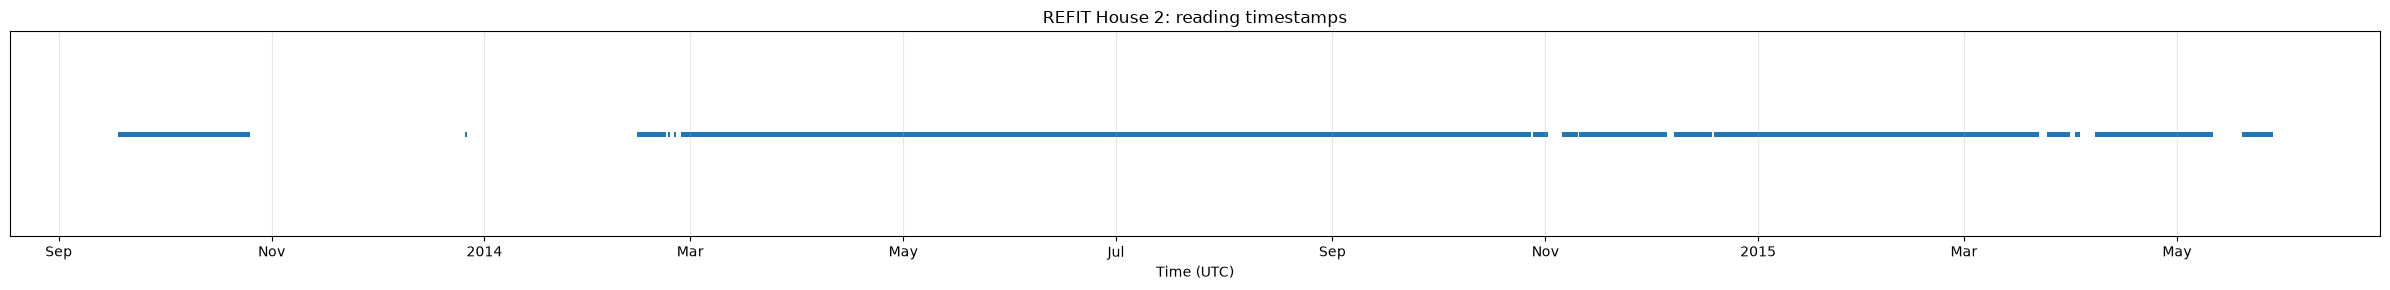

In [2]:
timestamps = pd.to_datetime(df["Unix"], unit="s", utc=True).sort_values()

fig, ax = plt.subplots(figsize=(24, 3))
ax.scatter(timestamps, [0] * len(timestamps), marker="|", s=12, linewidths=0.5)
ax.set_yticks([])
ax.set_xlabel("Time (UTC)")
ax.set_title("REFIT House 2: reading timestamps")
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=8, maxticks=20))
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "refit_house2_timeline.png", dpi=180, bbox_inches="tight")
plt.show()

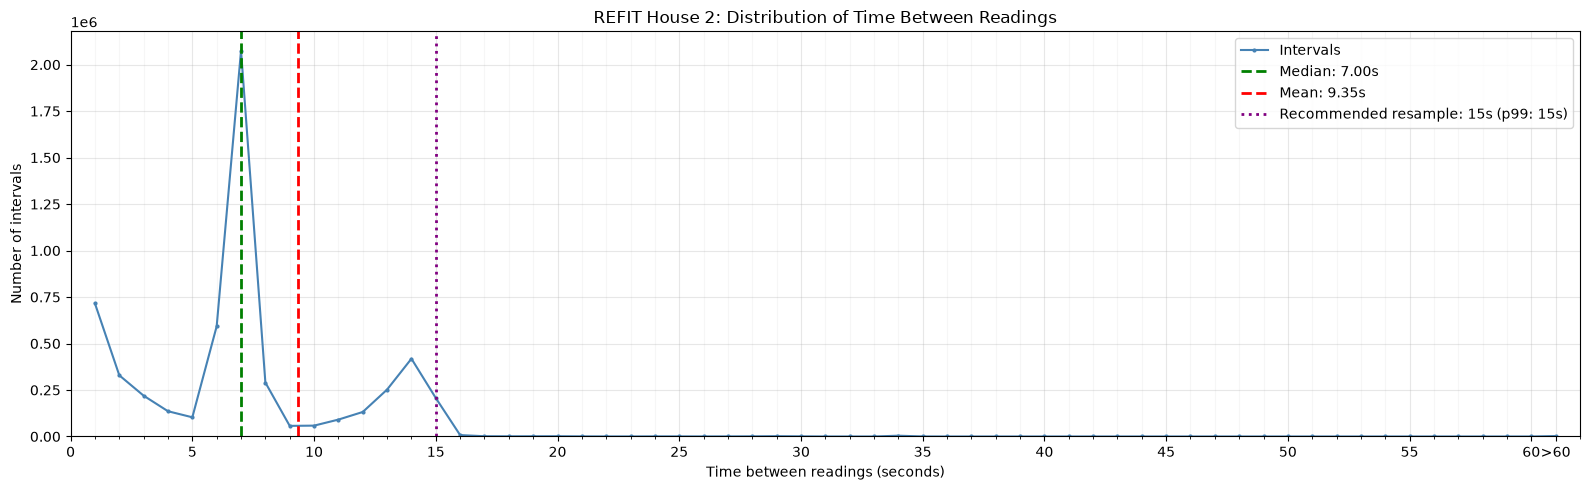

Recommended resample frequency: 15s; p99 interval = 15 seconds.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

unix_seconds = np.sort(df["Unix"].to_numpy(dtype=np.int64))
interval_seconds = np.diff(unix_seconds)
interval_seconds = interval_seconds[interval_seconds > 0]

mean = interval_seconds.mean()
median = np.median(interval_seconds)

limit = 60  # Giới hạn hiển thị chi tiết (giây)

# Count intervals for each second, with overflow bin > limit
counts = np.bincount(
    np.minimum(interval_seconds, limit + 1),
    minlength=limit + 2
)
x = np.arange(1, limit + 2)
y = counts[1:]

fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(x, y, marker=".", markersize=4, linewidth=1.5,
        color="steelblue", label="Intervals")

ax.axvline(min(median, limit + 1), color="green", linestyle="--",
           linewidth=2, label=f"Median: {median:.2f}s")

ax.axvline(min(mean, limit + 1), color="red", linestyle="--",
           linewidth=2, label=f"Mean: {mean:.2f}s")

p99 = np.quantile(interval_seconds, 0.99)
recommended_resample_seconds = 15
ax.axvline(recommended_resample_seconds, color="purple", linestyle=":",
           linewidth=2, label=f"Recommended resample: {recommended_resample_seconds}s (p99: {p99:.0f}s)")

ax.set_xlim(0, limit + 2)
ax.set_yscale("symlog", linthresh=1)

ax.xaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_minor_locator(MultipleLocator(1))

ticks = list(range(0, limit + 1, 5)) + [limit + 1]
ax.set_xticks(ticks)
ax.set_xticklabels([str(v) for v in ticks[:-1]] + [f">{limit}"])

ax.set_xlabel("Time between readings (seconds)")
ax.set_ylabel("Number of intervals")
ax.set_title("REFIT House 2: Distribution of Time Between Readings")
ax.set_yscale("linear")
ax.set_ylim(bottom=0)

ax.grid(alpha=0.3, which="major")
ax.grid(alpha=0.1, which="minor")
ax.legend()

fig.tight_layout()
fig.savefig(FIGURES_DIR / "refit_house2_inter_reading_intervals.png", dpi=180, bbox_inches="tight")
plt.show()

RESAMPLE_FREQ = "15s"
print(f"Recommended resample frequency: {RESAMPLE_FREQ}; p99 interval = {p99:.0f} seconds.")

In [4]:
measurement_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in {"Unix", "Issues"}
]
df_resampled = (
    df.assign(timestamp=pd.to_datetime(df["Unix"], unit="s", utc=True))
      .set_index("timestamp")[measurement_cols]
      .resample(RESAMPLE_FREQ)
      .mean()
)
print(f"Resampled at {RESAMPLE_FREQ}: {len(df_resampled):,} time bins.")
df_resampled.head()


Resampled at 15s: 3,556,311 time bins.


,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
timestamp,,,,,,,,,,
2013-09-17 22:08:00+00:00,695.0,88.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2013-09-17 22:08:15+00:00,694.0,88.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2013-09-17 22:08:30+00:00,701.0,88.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2013-09-17 22:08:45+00:00,699.0,88.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2013-09-17 22:09:00+00:00,696.0,87.666667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
empty_bin = df_resampled[measurement_cols].isna().all(axis=1)
run_id = (~empty_bin).cumsum()
empty_groups = pd.DataFrame({
    "timestamp": df_resampled.index[empty_bin],
    "run_id": run_id[empty_bin].to_numpy(),
})
gap_summary = empty_groups.groupby("run_id").agg(
    start=("timestamp", "min"),
    end=("timestamp", "max"),
    missing_bins=("timestamp", "size"),
)
gap_summary["duration"] = gap_summary["missing_bins"] * pd.Timedelta(RESAMPLE_FREQ)
gap_summary = gap_summary.sort_values("duration", ascending=False)
print(f"Found {len(gap_summary):,} contiguous empty intervals.")
gap_summary.head(20)


Found 14,956 contiguous empty intervals.


,start,end,missing_bins,duration
run_id,,,,
210720,2013-10-25 12:10:00+00:00,2013-12-26 12:44:30+00:00,357259,62 days 00:34:45
211521,2013-12-26 16:08:30+00:00,2014-02-13 16:08:00+00:00,282239,48 days 23:59:45
2607193,2015-05-10 23:36:15+00:00,2015-05-19 15:10:00+00:00,49816,8 days 15:34:00
2415416,2015-04-03 01:43:30+00:00,2015-04-07 10:18:15+00:00,25100,4 days 08:35:00
1610557,2014-11-01 14:04:15+00:00,2014-11-05 16:41:30+00:00,23670,4 days 02:37:30
1779016,2014-12-05 13:36:45+00:00,2014-12-08 00:06:45+00:00,14041,2 days 10:30:15
2370225,2015-03-22 08:16:00+00:00,2015-03-24 15:22:45+00:00,13228,2 days 07:07:00
220856,2014-02-24 16:52:00+00:00,2014-02-26 09:38:00+00:00,9785,1 days 16:46:15
2407447,2015-03-31 04:22:45+00:00,2015-04-01 16:26:00+00:00,8654,1 days 12:03:30


In [6]:
max_missing_duration = pd.Timedelta(minutes=3)
resample_interval = pd.Timedelta(RESAMPLE_FREQ)
df_ffill = df_resampled.copy()
filled_counts = {}

for col in measurement_cols:
    missing = df_resampled[col].isna()
    run_id = (~missing).cumsum()
    run_length = missing.groupby(run_id).transform("sum")
    fillable = missing & (run_length * resample_interval < max_missing_duration)
    previous_values = df_resampled[col].ffill()
    df_ffill.loc[fillable, col] = previous_values.loc[fillable]
    filled_counts[col] = int((missing & df_ffill[col].notna()).sum())

ffill_summary = pd.DataFrame({
    "missing_before": df_resampled[measurement_cols].isna().sum(),
    "filled": pd.Series(filled_counts),
    "missing_after": df_ffill[measurement_cols].isna().sum(),
})
print(f"Filled {ffill_summary['filled'].sum():,} values in runs shorter than {max_missing_duration}.")
ffill_summary


Filled 215,360 values in runs shorter than 0 days 00:03:00.


,missing_before,filled,missing_after
Aggregate,900209,21536,878673
Appliance1,900209,21536,878673
Appliance2,900209,21536,878673
Appliance3,900209,21536,878673
Appliance4,900209,21536,878673
Appliance5,900209,21536,878673
Appliance6,900209,21536,878673
Appliance7,900209,21536,878673
Appliance8,900209,21536,878673
Appliance9,900209,21536,878673


## Báo cáo độ phủ dữ liệu — REFIT House 2

Sau khi loại các dòng có `Issues = 1`, resample theo 15 giây tạo **3.556.311 bin thời gian**. Trong đó, **900.209 bin (25,3%)** không có bản ghi. Có tổng cộng **14.956 khoảng trống liên tục**: 569 kéo dài ít nhất 3 phút, 83 ít nhất 1 giờ và 11 ít nhất 1 ngày. Forward fill các chuỗi ngắn hơn 3 phút điền **21.536 bin cho mỗi cột đo**; các khoảng dài hơn hoặc bằng 3 phút vẫn để thiếu.

Hai khoảng trống dài nhất:

| Bắt đầu (UTC) | Kết thúc (UTC) | Thời lượng |
|---|---|---:|
| 2013-10-25 12:10:00 | 2013-12-26 12:44:30 | 62 ngày 00:34:45 |
| 2013-12-26 16:08:30 | 2014-02-13 16:08:00 | 48 ngày 23:59:45 |

Hai khoảng này cùng nằm trong một **cửa sổ gián đoạn lớn** từ **2013-10-25 12:10:00 UTC** đến **2014-02-13 16:08:00 UTC**. Tuy nhiên, cửa sổ này không hoàn toàn trống: ở giữa có **1.293 bản ghi**, từ 12:44:53 đến 16:08:21 UTC ngày 26/12/2013, trong khoảng 3 giờ 23 phút 28 giây.

Hai dataframe `df_before_gap` và `df_after_gap` chứa dữ liệu trước và sau cửa sổ gián đoạn lớn. Đoạn dữ liệu ngắn ở giữa không nằm trong hai dataframe này; dataframe nguồn `df` vẫn được giữ nguyên.

Các gap biểu thị **thiếu quan sát**, không có nghĩa là công suất bằng 0. Chỉ từ timestamp thì chưa thể xác định nguyên nhân gián đoạn.

Ở bước clipping cuối, giá trị đo nhỏ hơn 5 W (bao gồm số âm) được đưa về 0 W; giá trị lớn hơn 6000 W được chặn ở 6000 W. Các giá trị thiếu NaN được giữ nguyên để không làm mất dấu gap.


In [7]:
# Split the issue-filtered raw dataframe around the long interruption window.
# The source dataframe `df` is left unchanged.
interruption_start = pd.Timestamp("2013-10-25 12:10:00", tz="UTC").timestamp()
interruption_end = pd.Timestamp("2014-02-13 16:08:00", tz="UTC").timestamp()

df_before_gap = df.loc[df["Unix"] < interruption_start].copy()
df_after_gap = df.loc[df["Unix"] > interruption_end].copy()

print(f"df_before_gap: {len(df_before_gap):,} rows")
print(f"df_after_gap: {len(df_after_gap):,} rows")
print(f"Rows retained in original df but outside these two segments: "
      f"{len(df) - len(df_before_gap) - len(df_after_gap):,}")


df_before_gap: 481,856 rows
df_after_gap: 5,221,933 rows
Rows retained in original df but outside these two segments: 1,293


In [8]:
# Clip power readings across the raw, resampled, filled, and split dataframes.
MIN_POWER_W = 5
MAX_POWER_W = 10_000

def clip_power_values(frame):
    clipped = frame.copy()
    values = clipped[measurement_cols]
    clipped_values = values.clip(upper=MAX_POWER_W)
    clipped.loc[:, measurement_cols] = clipped_values.mask(
        values.notna() & (values < MIN_POWER_W), 0
    )
    return clipped

frames_to_clip = {
    "df": df,
    "df_resampled": df_resampled,
    "df_ffill": df_ffill,
    "df_before_gap": df_before_gap,
    "df_after_gap": df_after_gap,
}
clip_rows = []
for name, frame in frames_to_clip.items():
    values = frame[measurement_cols]
    clip_rows.append({
        "dataframe": name,
        "values_below_5W_set_to_zero": int((values < MIN_POWER_W).sum().sum()),
        "values_above_10000W_capped": int((values > MAX_POWER_W).sum().sum()),
    })

clip_summary = pd.DataFrame(clip_rows).set_index("dataframe")
df = clip_power_values(df)
df_resampled = clip_power_values(df_resampled)
df_ffill = clip_power_values(df_ffill)
df_before_gap = clip_power_values(df_before_gap)
df_after_gap = clip_power_values(df_after_gap)
print("Applied clipping: values below 5 W -> 0 W; values above 10000 W -> 10000 W.")
clip_summary


Applied clipping: values below 5 W -> 0 W; values above 10000 W -> 10000 W.


,values_below_5W_set_to_zero,values_above_10000W_capped
dataframe,,
df,47034966,34738
df_resampled,21890902,16082
df_ffill,22068431,16120
df_before_gap,3972610,2764
df_after_gap,43051546,31974


In [9]:
# Save the two clipped, issue-filtered raw data segments as CSV files.
PREPROCESSED_DIR = Path("../preprocessed")
PREPROCESSED_DIR.mkdir(parents=True, exist_ok=True)

before_path = PREPROCESSED_DIR / "refit_house2_before_gap.csv"
after_path = PREPROCESSED_DIR / "refit_house2_after_gap.csv"
df_before_gap.to_csv(before_path, index=False)
df_after_gap.to_csv(after_path, index=False)

print(f"Saved {len(df_before_gap):,} rows to {before_path}")
print(f"Saved {len(df_after_gap):,} rows to {after_path}")


Saved 481,856 rows to ..\preprocessed\refit_house2_before_gap.csv
Saved 5,221,933 rows to ..\preprocessed\refit_house2_after_gap.csv


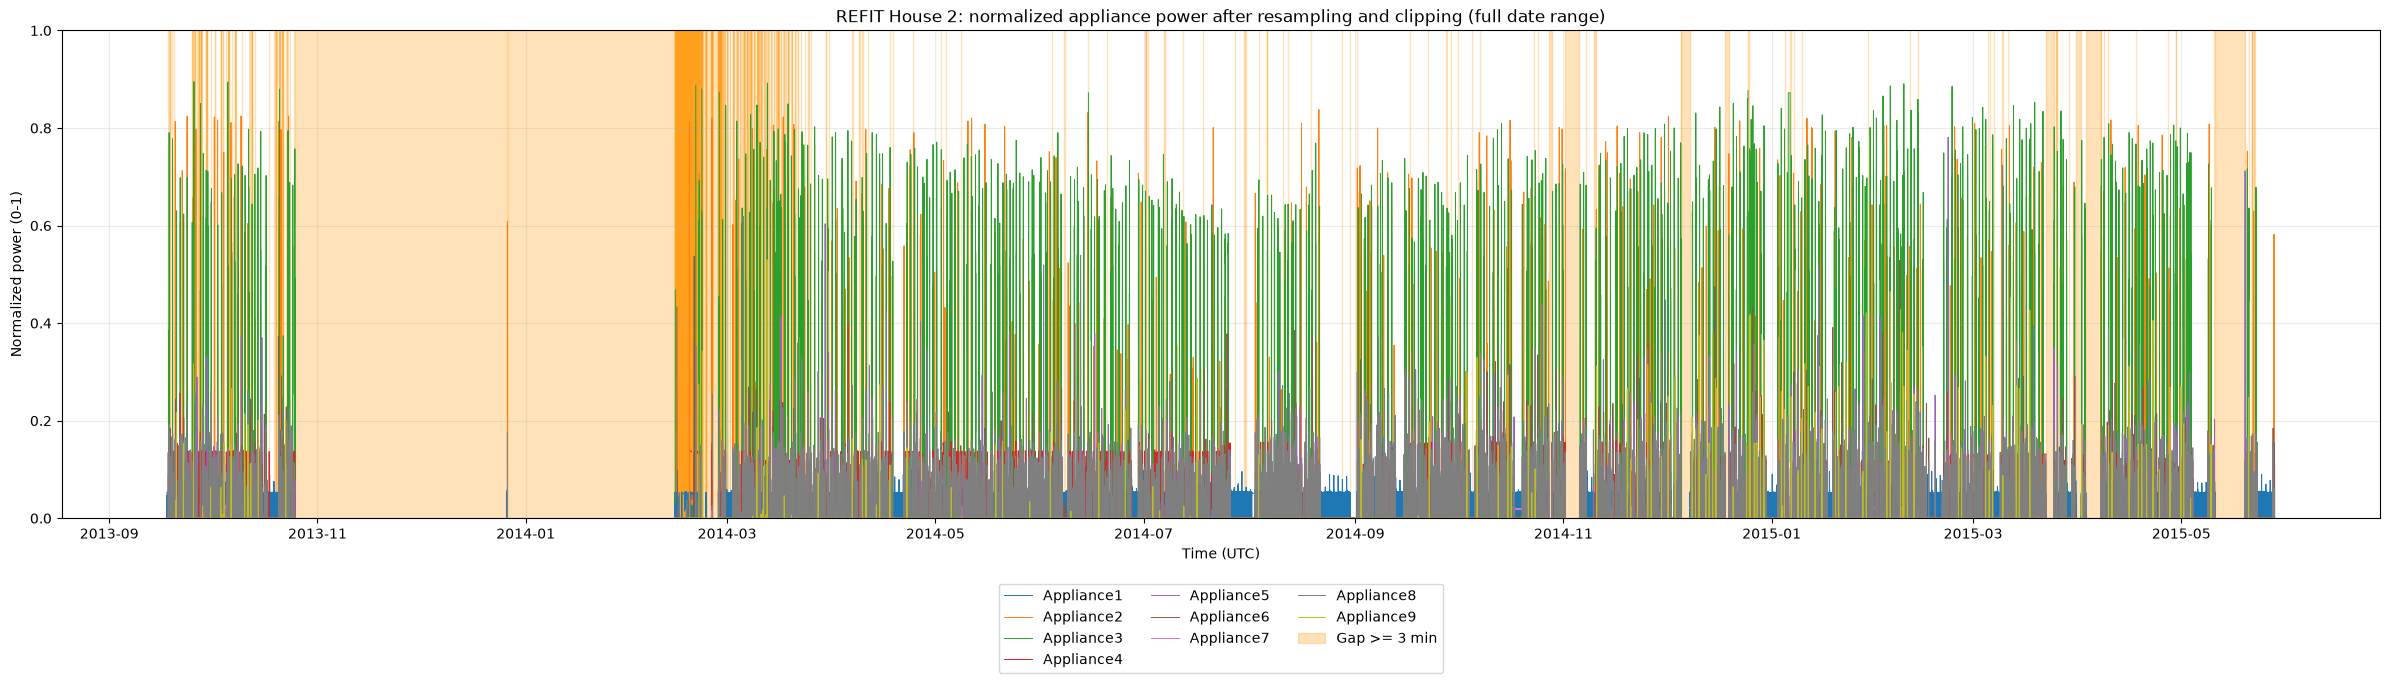

In [10]:
# Plot all appliances over the full date range on one power axis.
# Aggregate to 15-minute means for display only; df_resampled remains at 15 seconds.
plot_cols = [col for col in measurement_cols if col.startswith("Appliance")]
PLOT_AGGREGATION = "15min"
MIN_GAP_TO_SHADE = pd.Timedelta(minutes=3)

def shade_long_gaps(ax, frame):
    empty_bin = frame[plot_cols].isna().all(axis=1)
    run_id = (~empty_bin).cumsum()
    groups = pd.DataFrame({
        "timestamp": frame.index[empty_bin],
        "run_id": run_id[empty_bin].to_numpy(),
    })
    gaps = groups.groupby("run_id").agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        missing_bins=("timestamp", "size"),
    )
    gaps["duration"] = gaps["missing_bins"] * pd.Timedelta(RESAMPLE_FREQ)
    visible_gaps = gaps.loc[gaps["duration"] >= MIN_GAP_TO_SHADE]
    for i, gap in enumerate(visible_gaps.itertuples()):
        ax.axvspan(
            gap.start,
            gap.end + pd.Timedelta(RESAMPLE_FREQ),
            color="#ff9f1c",
            alpha=0.30,
            label="Gap >= 3 min" if i == 0 else "_nolegend_",
        )

appliance_min = df_resampled[plot_cols].min()
appliance_range = (df_resampled[plot_cols].max() - appliance_min).replace(0, 1)
plot_resampled_view = (
    df_resampled[plot_cols].resample(PLOT_AGGREGATION).mean() - appliance_min
) / appliance_range
fig, ax = plt.subplots(figsize=(24, 7))
for col in plot_cols:
    ax.plot(plot_resampled_view.index, plot_resampled_view[col], linewidth=0.7, label=col)
shade_long_gaps(ax, df_resampled)
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Normalized power (0-1)")
ax.set_ylim(0, 1)
ax.set_title("REFIT House 2: normalized appliance power after resampling and clipping (full date range)")
ax.grid(alpha=0.25)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "refit_house2_resampled_all_appliances.png", dpi=180, bbox_inches="tight")
plt.show()


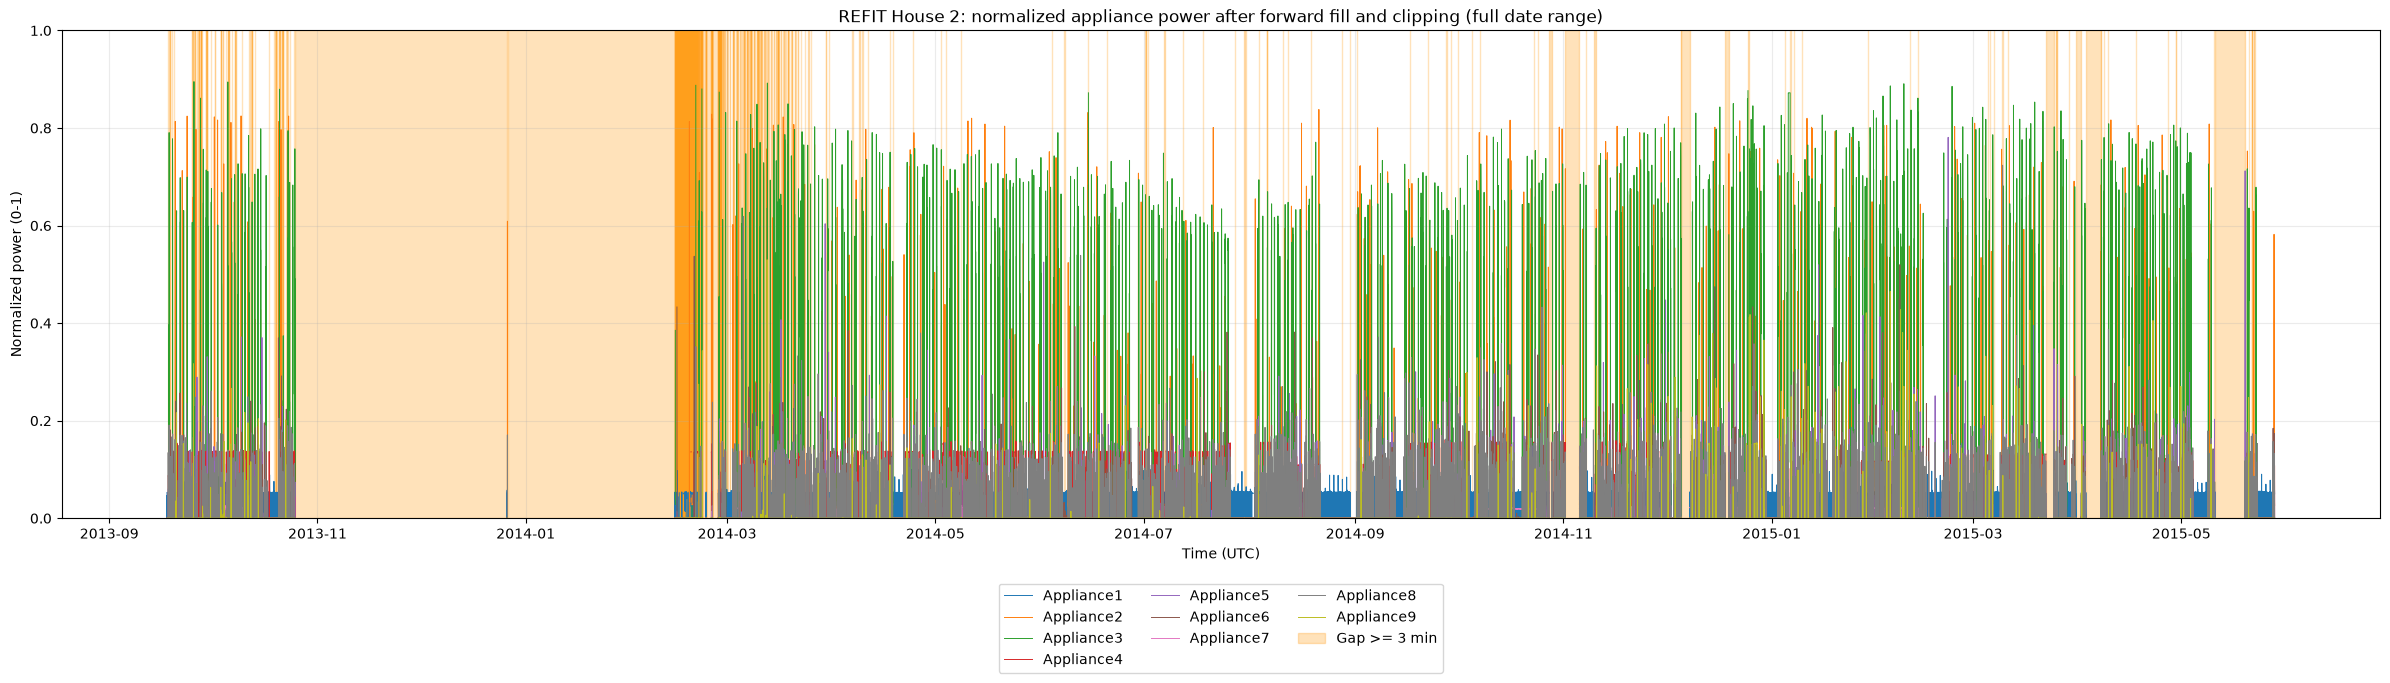

In [11]:
# Plot the same full date range after bounded forward filling.
plot_ffilled_view = (
    df_ffill[plot_cols].resample(PLOT_AGGREGATION).mean() - appliance_min
) / appliance_range
fig, ax = plt.subplots(figsize=(24, 7))
for col in plot_cols:
    ax.plot(plot_ffilled_view.index, plot_ffilled_view[col], linewidth=0.7, label=col)
shade_long_gaps(ax, df_ffill)
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Normalized power (0-1)")
ax.set_ylim(0, 1)
ax.set_title("REFIT House 2: normalized appliance power after forward fill and clipping (full date range)")
ax.grid(alpha=0.25)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "refit_house2_forward_filled_all_appliances.png", dpi=180, bbox_inches="tight")
plt.show()
